# Exploration des données
Projet : prédire l'état de la vanne d'un système hydraulique à partir des capteurs **PS2** (pression) et **FS1** (débit).

## 1. Chargement des données et statistiques descriptives

In [189]:
%load_ext autoreload
%autoreload 2

import pandas as pd
from matplotlib import pyplot as plt

from src.utils import load_data, save_data
from src.utils import (
    build_features, drop_constant_features, drop_correlated_features, count_outliers_iqr,
)
from src.utils import make_binary_target, missing_summary, class_distribution, split_data
from src.utils import (
    plot_class_distribution, plot_correlation_matrix, plot_histograms, plot_boxplots,
)

PS2 = load_data("data/raw/PS2.txt")
FS1 = load_data("data/raw/FS1.txt")
profile = load_data("data/raw/profile.txt")

print("PS2    :", PS2.shape, "(cycles x points)")
print("FS1    :", FS1.shape, "(cycles x points)")
print("profile:", profile.shape, "(cycles x conditions)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PS2    : (2205, 6000) (cycles x points)
FS1    : (2205, 600) (cycles x points)
profile: (2205, 5) (cycles x conditions)


In [190]:
profile.columns = ["cooler", "valve", "pump", "accumulator", "stable"]
profile.head()

,cooler,valve,pump,accumulator,stable
0,3,100,0,130,1
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1


In [191]:
# Informations globales sur les données de chaque capteur
for name, df in {"PS2": PS2, "FS1": FS1}.items():
    print(f"--- {name}")
    df.info(verbose=False)

--- PS2
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Columns: 6000 entries, 0 to 5999
dtypes: float64(6000)
memory usage: 100.9 MB
--- FS1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Columns: 600 entries, 0 to 599
dtypes: float64(600)
memory usage: 10.1 MB


In [170]:
# Statistiques globales de chaque capteur (toutes les mesures de tous les cycles)
pd.DataFrame({
    "PS2": pd.Series(PS2.to_numpy().ravel()).describe(),
    "FS1": pd.Series(FS1.to_numpy().ravel()).describe(),
})

,PS2,FS1
count,1.323000e+07,1.323000e+06
mean,1.093799e+02,6.198549e+00
std,4.810317e+01,3.213827e+00
min,0.000000e+00,0.000000e+00
25%,1.185400e+02,7.339000e+00
50%,1.257000e+02,7.641000e+00
75%,1.304100e+02,7.796000e+00
max,1.677700e+02,2.047900e+01


In [192]:
profile.describe().T

,count,mean,std,min,25%,50%,75%,max
cooler,2205.0,41.240816,42.383143,3.0,3.0,20.0,100.0,100.0
valve,2205.0,90.693878,10.681802,73.0,80.0,100.0,100.0,100.0
pump,2205.0,0.669388,0.817233,0.0,0.0,0.0,1.0,2.0
accumulator,2205.0,107.199546,16.435848,90.0,90.0,100.0,130.0,130.0
stable,2205.0,0.342857,0.474772,0.0,0.0,0.0,1.0,1.0


## 2. Valeurs manquantes et valeurs aberrantes

In [194]:
missing_summary({"PS2": PS2, "FS1": FS1, "profile": profile})

,valeurs_manquantes,cellules
PS2,0,13230000
FS1,0,1323000
profile,0,11025


In [173]:
# Chaque cycle (6000 / 600 points) est résumé par des statistiques
X = build_features({"ps2": PS2, "fs1": FS1})
print("Valeurs manquantes dans X :", X.isna().sum().sum())
print("Dimension de X :", X.shape)
X['qmm'] = X['ps2_mean'] / X['fs1_mean']
X.head()

Valeurs manquantes dans X : 0
Dimension de X : (2205, 22)


,ps2_min,ps2_max,ps2_mean,ps2_std,ps2_median,ps2_q25,ps2_q75,ps2_iqr,ps2_rms,ps2_skew,...,fs1_mean,fs1_std,fs1_median,fs1_q25,fs1_q75,fs1_iqr,fs1_rms,fs1_skew,fs1_kurtosis,qmm
0,0.0,156.99,109.466914,47.110581,129.365,120.1900,130.54,10.3500,119.173873,-1.837853,...,6.709815,3.012914,7.836,7.68775,7.93400,0.24625,7.355220,-1.399797,1.661736,16.314446
1,0.0,157.56,109.354890,47.041690,129.385,120.1300,130.38,10.2500,119.043743,-1.838351,...,6.715315,3.003742,7.853,7.72400,7.95225,0.22825,7.356488,-1.446472,1.637921,16.284402
2,0.0,156.97,109.158845,46.988144,129.325,120.0400,130.13,10.0900,118.842497,-1.837545,...,6.718522,3.011735,7.847,7.69875,7.95425,0.25550,7.362682,-1.431863,1.624573,16.247450
3,0.0,156.44,109.064807,46.968307,128.865,119.9600,130.02,10.0600,118.748280,-1.837120,...,6.720565,3.017658,7.843,7.71100,7.95425,0.24325,7.366970,-1.406670,1.655717,16.228518
4,0.0,158.13,108.931434,46.871040,129.000,119.8375,129.82,9.9825,118.587317,-1.837496,...,6.690308,3.009040,7.831,7.69025,7.94325,0.25300,7.335840,-1.422662,1.619443,16.281975


In [174]:
# Valeurs aberrantes : règle de l'IQR (hors de [Q1 - 1.5*IQR ; Q3 + 1.5*IQR])
count_outliers_iqr(X)

,n_outliers,%
fs1_iqr,265,12.0
ps2_iqr,265,12.0
fs1_std,250,11.3
ps2_skew,241,10.9
qmm,240,10.9
fs1_q25,240,10.9
fs1_median,240,10.9
fs1_mean,240,10.9
fs1_skew,240,10.9
ps2_kurtosis,240,10.9


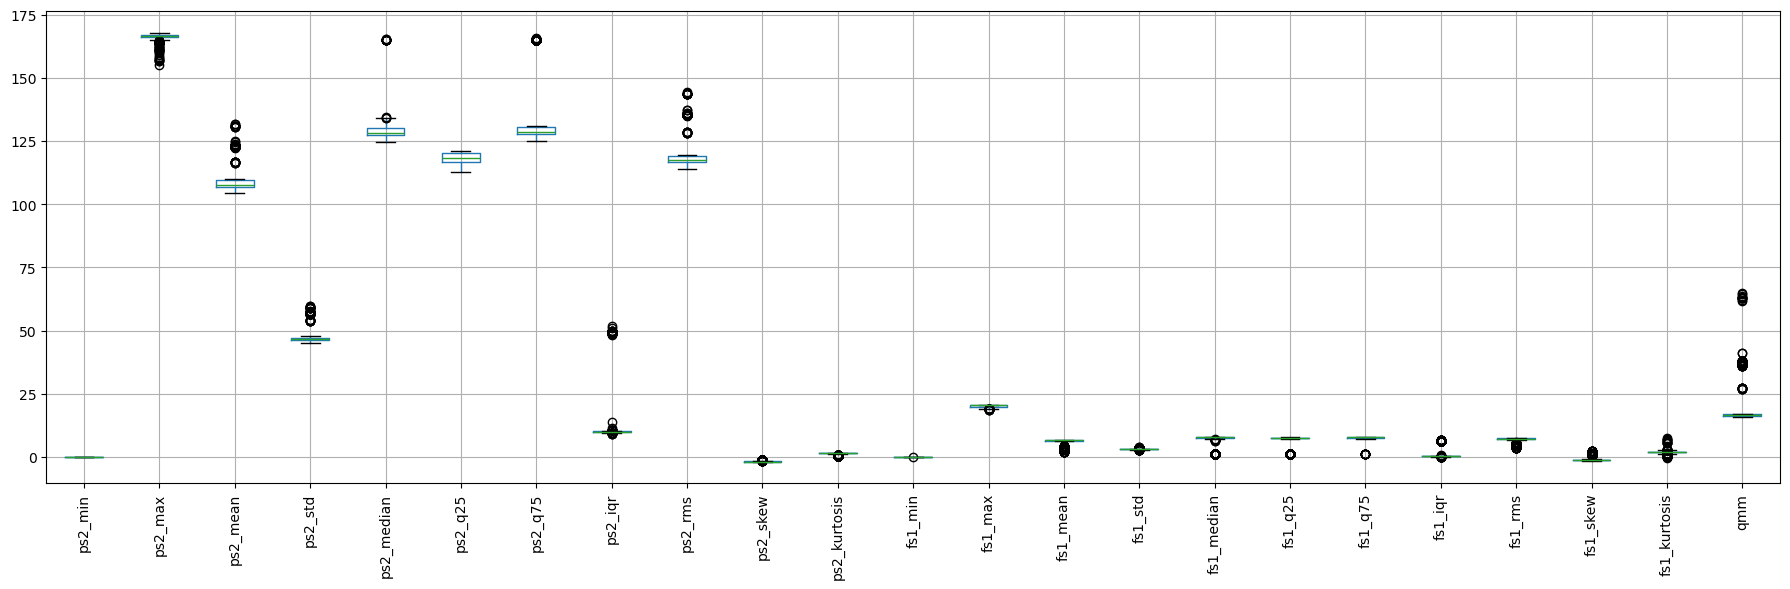

In [175]:
plot_boxplots(X, save_as="boxplots_features.png")

**Conclusion** : beaucoup de valeurs aberrantes, surtout sur FS1. On les **conserve** : elles correspondent probablement à des états particuliers de la vanne (ce sont des signaux physiques, pas des erreurs de mesure). On standardise les features avant l'entraînement des modèles sensibles à l'échelle (KNN, SVM, régression logistique).

## 3. Variables catégorielles

In [176]:
print(PS2.dtypes.unique(), FS1.dtypes.unique())
profile.dtypes

[dtype('float64')] [dtype('float64')]


cooler         int64
valve          int64
pump           int64
accumulator    int64
stable         int64
dtype: object

In [177]:
profile.nunique()

cooler         3
valve          4
pump           3
accumulator    4
stable         2
dtype: int64

**Conclusion** : toutes les variables sont numériques, il n'y a **aucune variable catégorielle à encoder** dans les features. Les colonnes de `profile` sont des codes numériques de conditions (par exemple la vanne : 100, 90, 80, 73 %). Seule la cible est transformée, à l'étape suivante.

## 4. Transformation en classification binaire

La colonne `valve` donne l'état de la vanne : 100 % (fonctionnement optimal) ou dégradée (90, 80, 73 %).
On définit `y = 1` si la vanne est à 100 %, `0` sinon.

In [178]:
y = make_binary_target(profile["valve"], positive_value=100, name="valve_optimal")
y.head()

0    1
1    1
2    1
3    1
4    1
Name: valve_optimal, dtype: int64

## 5. Distribution des classes

In [179]:
class_distribution(y)

,n,%
valve_optimal,,
0,1080,49.0
1,1125,51.0


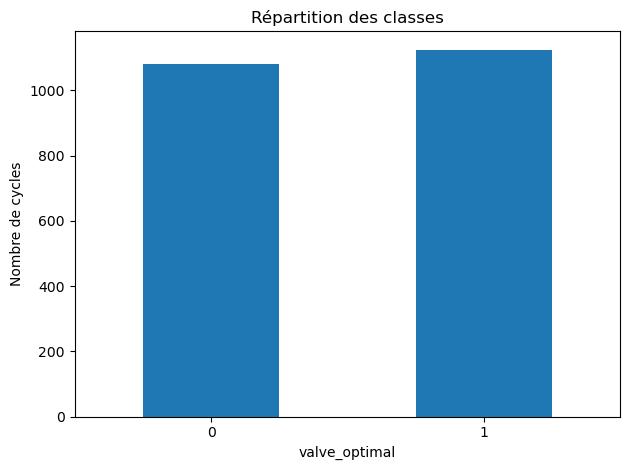

,n,%
valve_optimal,,
0,1080,49.0
1,1125,51.0


In [180]:
plot_class_distribution(y, save_as="repartition_classes_vanne.png")

**Conclusion** : les classes sont quasiment équilibrées sur l'ensemble du jeu (environ 51 % / 49 %). Le déséquilibre éventuel viendra du **découpage train/test** (traité dans l'étape suivante : découpage stratifié).

## 6. Sélection des features

In [181]:
# Features constantes ou quasi constantes
X, constant_cols = drop_constant_features(X, threshold=1e-3)
print("Supprimées :", constant_cols)

Supprimées : ['ps2_min', 'fs1_min']


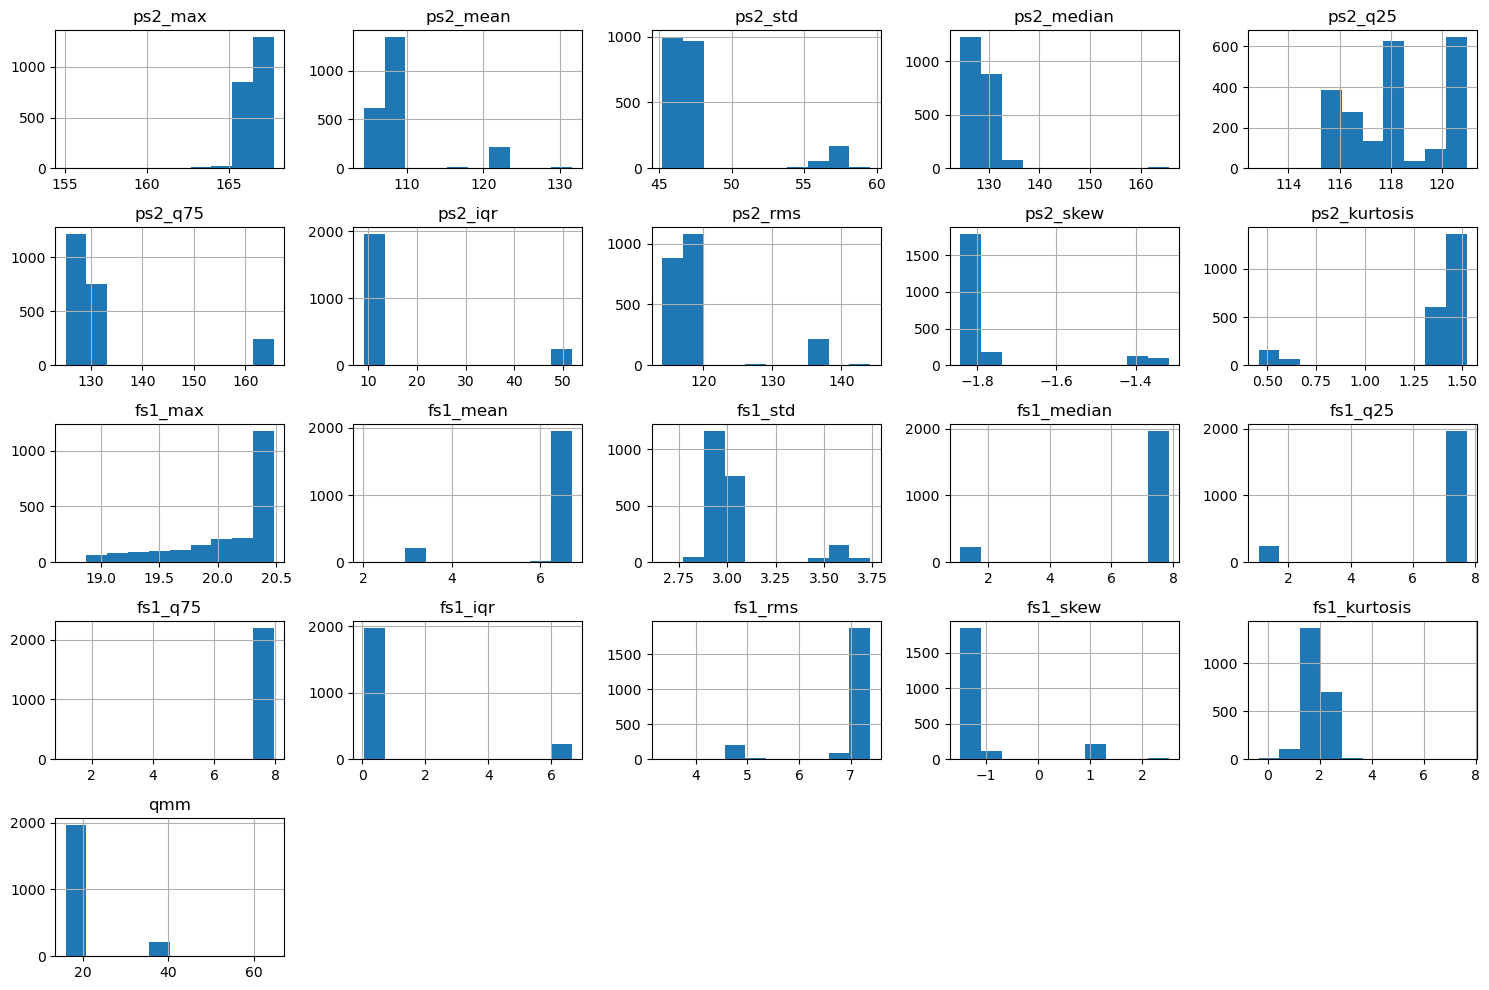

In [182]:
plot_histograms(X, save_as="histogramme_features.png")

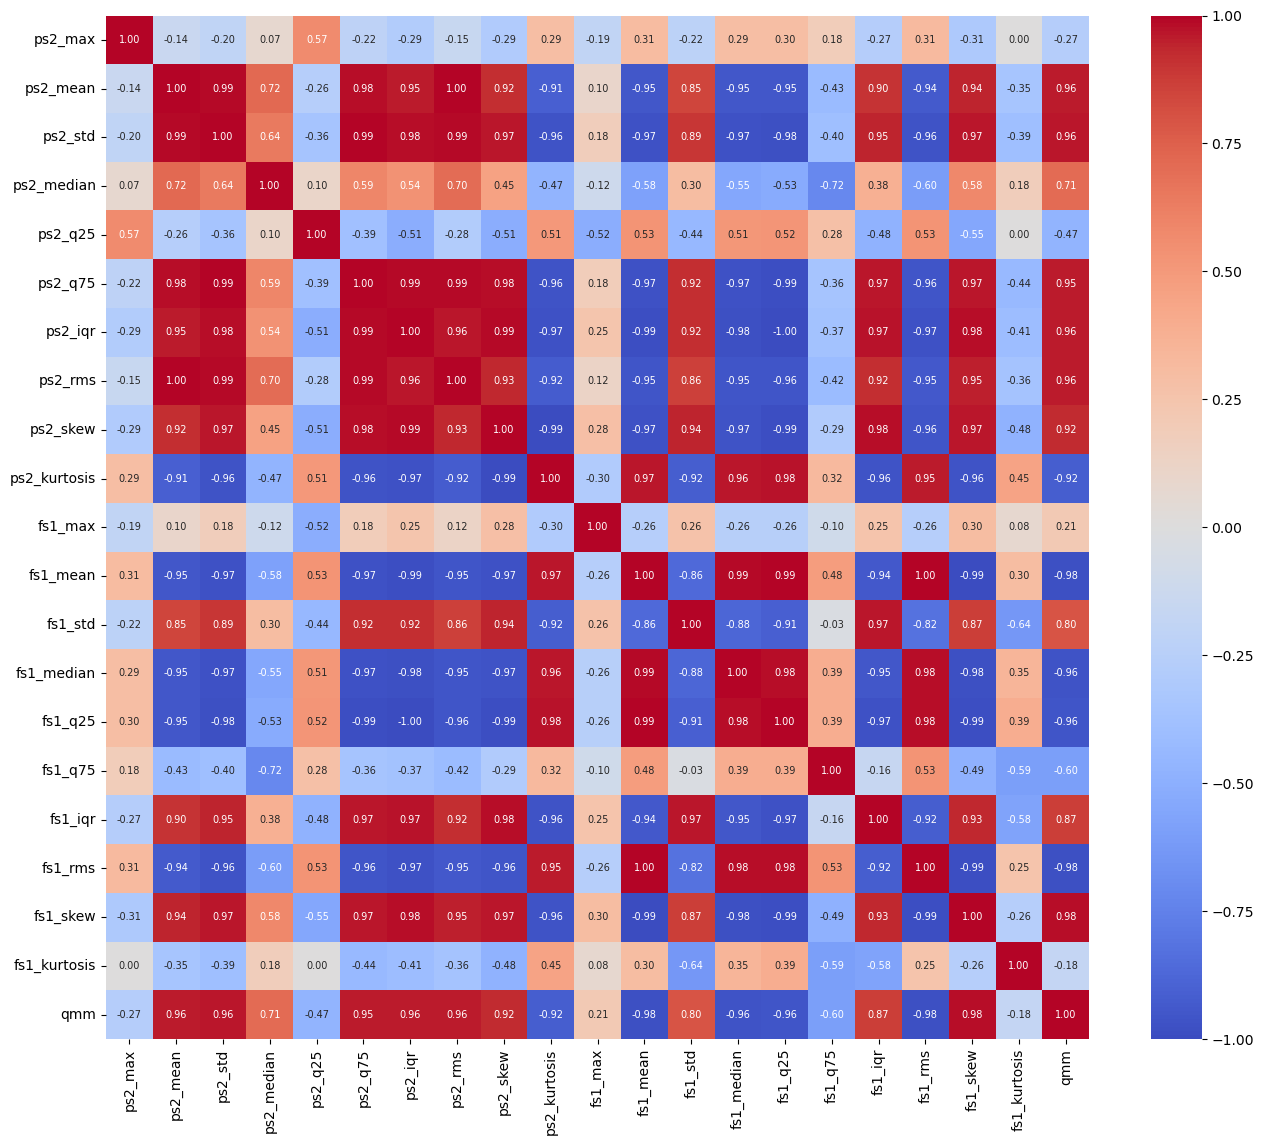

In [183]:
plot_correlation_matrix(X, save_as="matrice_correlation.png")

In [184]:
# Une seule feature par paire fortement corrélée (|corr| > 0.85)
X, to_drop = drop_correlated_features(X, threshold=0.85)
print("Supprimées :", to_drop)
print("Features conservées :", X.shape[1], list(X.columns))

Supprimées : ['ps2_std', 'ps2_q75', 'ps2_iqr', 'ps2_rms', 'ps2_skew', 'ps2_kurtosis', 'fs1_mean', 'fs1_std', 'fs1_median', 'fs1_q25', 'fs1_iqr', 'fs1_rms', 'fs1_skew', 'qmm']
Features conservées : 7 ['ps2_max', 'ps2_mean', 'ps2_median', 'ps2_q25', 'fs1_max', 'fs1_q75', 'fs1_kurtosis']


In [185]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
ps2_max,2205.0,166.520517,0.977997,155.040000,166.180000,166.650000,167.100000,167.770000
ps2_mean,2205.0,109.379906,4.986585,104.406307,106.962382,107.730169,109.421612,131.589089
ps2_median,2205.0,128.677664,3.469525,124.445000,127.215000,127.965000,129.950000,165.400000
ps2_q25,2205.0,118.231824,1.792053,112.840000,116.610000,118.090000,120.260000,120.960000
fs1_max,2205.0,20.130214,0.451934,18.698000,19.881000,20.363000,20.479000,20.479000
fs1_q75,2205.0,7.693922,0.492671,1.154000,7.586000,7.754000,7.888000,7.954250
fs1_kurtosis,2205.0,1.957524,0.470250,-0.350849,1.817875,1.945484,2.128718,7.660421


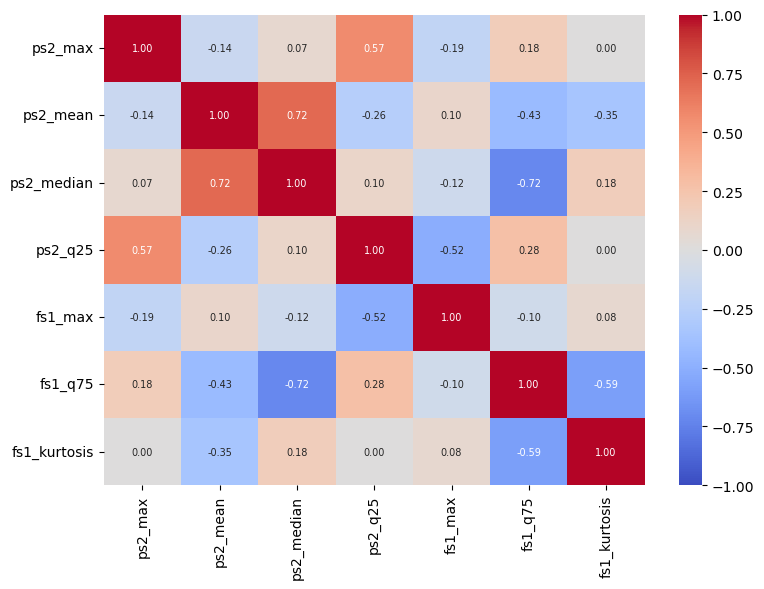

In [200]:
plot_correlation_matrix(X, save_as="matrice_correlation_finale.png")

In [187]:
# Découpage mélangé et stratifié (test = 15 %)
x_train, x_test, y_train, y_test = split_data(X, y, test_size=0.2)
pd.concat({"train": class_distribution(y_train), "test": class_distribution(y_test)}, axis=1)

train       test      
                  n     %    n     %
valve_optimal                       
0               864  49.0  216  49.0
1               900  51.0  225  51.0

## 7. Sauvegarde

In [188]:
print(X.shape, y.shape)
save_data(x_train, x_test, y_train, y_test, name="stats")

(2205, 7) (2205,)


WindowsPath('C:/Users/noumo/Desktop/EFREI/Machine learning/projetML/hydraulic-valve-predictive-maintenance/data/processed/stats')